# Prediccion de Cancelacion de Tiquetes en Agencias de Transporte

## Descripcion del problema

Las agencias de transporte enfrentan perdidas economicas significativas cuando un pasajero cancela su reserva de ultimo momento o simplemente no se presenta. Este modelo busca predecir, con base en las caracteristicas de una reserva, si el pasajero la cancelara antes de que ocurra el viaje.

El dataset proviene de una competencia de Kaggle y contiene informacion real de reservas de una agencia de transporte, incluyendo tiquetes de bus, tren y avion. Cada fila representa una reserva individual realizada por un usuario.

## Variables de entrada (features)

| Variable | Descripcion |
|---|---|
| `dias_anticipacion` | Dias entre la compra del tiquete y la fecha de salida |
| `Price` | Precio pagado por el tiquete |
| `Discounts` | Descuento aplicado a la reserva |
| `Gender-Male` | Genero del comprador (1 = hombre, 0 = mujer) |
| `DomesticFlight` | Si el viaje es nacional (1) o internacional (0) |
| `ModeOfTravel` | Medio de transporte: Bus (0), avion de vuelo internacional (1), avion (2), tren (3) |
| `ReasonForTrip` | Motivo del viaje: trabajo o personal |
| `StatusofReserve` | Estado interno de la reserva al momento del registro |

## Variable objetivo (target)

- **`Cancelled`**: `1` si el pasajero cancelo la reserva, `0` si se presento normalmente.

El modelo aprendera patrones historicos para clasificar nuevas reservas como riesgo de cancelacion alto o bajo, permitiendo a la agencia tomar decisiones preventivas como ajuste de precios, overbooking controlado o alertas tempranas al equipo operativo.

In [1]:
# Manipulacion y analisis de datos tabulares
import pandas as pd

# Operaciones numericas y generacion de arrays
import numpy as np

# Graficas base
import matplotlib.pyplot as plt

# Graficas estadisticas sobre matplotlib
import seaborn as sns

# Modelo Random Forest para clasificacion supervisada
from sklearn.ensemble import RandomForestClassifier

# Division del dataset en entrenamiento y prueba
from sklearn.model_selection import train_test_split, cross_val_score

# Codificacion de variables categoricas a numericas
from sklearn.preprocessing import LabelEncoder

# Metricas de evaluacion del modelo
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

print('Librerias importadas correctamente')

Librerias importadas correctamente


In [3]:
# Subir el archivo train.csv desde el computador
#from google.colab import files
#files.upload() 

In [4]:
# Cargar el dataset
df_raw = pd.read_csv('train.csv')

print(f'Dataset cargado: {df_raw.shape[0]:,} registros, {df_raw.shape[1]} columnas')
print()
df_raw.head(5)

Dataset cargado: 70,711 registros, 22 columnas



,ID,TimeOfCreation,TimeOfDeparture,BillNo.,TicketNo.,StatusofReserve,UserID,Gender-Male,Price,Discounts,...,DomesticFlight,TypeOfVehicle,VehicleClass,ReasonForTrip,ModeOfTravel,PassportNumberHashed,EmailHashed,BuyerMobile,NationalCode,Cancelled
0,100505,2022-07-06 06:02:12.407,2022-07-06 10:30:00,38131030,7359427.0,3,NaN,True,850000.0,0.0,...,1,اسکانیا کلاسیک ۳۲نفره,True,Int,Bus,NaN,51726016301ff645e88be828ae6277a23ea22fcab14880...,965396967731,103017017,0
1,100506,2022-09-11 13:51:08.797,2022-09-13 14:45:00,39115817,3002688.0,2,891421.0,True,5338000.0,0.0,...,1,5ستاره اكونومي سلامت فدك,NaN,Int,Train,NaN,e5a486781dac75d915322638102f2bafd512687be5d814...,452719996887,261570051,0
2,100507,2022-08-01 14:45:28.883,2022-08-24 20:39:00,38510118,2927990.0,4,NaN,False,1355000.0,0.0,...,1,3 ستاره 6 تخته کوير,NaN,Work,Train,NaN,NaN,116690640411,957707173,1
3,100508,2022-09-29 10:41:28.120,2022-09-29 20:30:00,39403118,7663791.0,3,264716.0,True,2540000.0,0.0,...,1,VIP 2+1 / یک وعده غذای گرم,True,Work,Bus,NaN,b565e2250ec788a19435ec680fd11c47f77f0c92587bf4...,642337257287,264441760,0
4,100509,2022-10-03 16:43:35.277,2022-10-04 12:15:00,39470084,7681449.0,3,76842.0,True,1690000.0,0.0,...,1,VIPمارال تخت شو با شارژر اختصاصی,True,Int,Bus,NaN,aa472b493e4499370b308a11358755bef6c4b04def69f2...,138128253547,765571492,0


In [5]:
# --- LIMPIEZA Y PREPARACION DEL DATASET ---

df = df_raw.copy()

# Calcular dias de anticipacion entre compra y salida
# Es la variable mas importante conceptualmente: quien compra tarde, cancela mas
df['TimeOfCreation']  = pd.to_datetime(df['TimeOfCreation'],  errors='coerce')
df['TimeOfDeparture'] = pd.to_datetime(df['TimeOfDeparture'], errors='coerce')
df['dias_anticipacion'] = (df['TimeOfDeparture'] - df['TimeOfCreation']).dt.total_seconds() / 86400
df['dias_anticipacion'] = df['dias_anticipacion'].clip(lower=0)  # eliminar valores negativos

# Seleccionar columnas utiles (se descartan hashes, IDs y columnas con mas del 50% de nulos)
columnas = [
    'dias_anticipacion',
    'Price',
    'Discounts',
    'Gender-Male',
    'DomesticFlight',
    'ModeOfTravel',
    'ReasonForTrip',
    'StatusofReserve',
    'Cancelled'
]

df = df[columnas].dropna().reset_index(drop=True)

# Codificar variables de texto a numeros
le = LabelEncoder()
for col in ['ModeOfTravel', 'ReasonForTrip']:
    df[col] = le.fit_transform(df[col])

# Convertir booleanos a enteros si aplica
df['Gender-Male']    = df['Gender-Male'].astype(int)
df['DomesticFlight'] = df['DomesticFlight'].astype(int)

print(f'Registros despues de limpieza: {df.shape[0]:,}')
print()
print('Vista previa del dataset limpio:')
display(df.head(10))

print()
print('Distribucion del target (Cancelled):')
conteo = df['Cancelled'].value_counts()
print(f'   No cancelaron (0): {conteo[0]:,} pasajeros  ({conteo[0]/len(df):.1%})')
print(f'   Si cancelaron  (1): {conteo[1]:,} pasajeros  ({conteo[1]/len(df):.1%})')
print()
print('Nota: el dataset esta desbalanceado. El modelo usara class_weight="balanced" para compensarlo.')

Registros despues de limpieza: 70,711

Vista previa del dataset limpio:


,dias_anticipacion,Price,Discounts,Gender-Male,DomesticFlight,ModeOfTravel,ReasonForTrip,StatusofReserve,Cancelled
0,0.185968,850000.0,0.0,1,1,0,0,3,0
1,2.037398,5338000.0,0.0,1,1,3,0,2,0
2,23.245499,1355000.0,0.0,0,1,3,1,4,1
3,0.408702,2540000.0,0.0,1,1,0,1,3,0
4,0.813481,1690000.0,0.0,1,1,0,0,3,0
5,12.433695,3403000.0,0.0,0,1,3,0,2,0
6,3.169255,1158500.0,0.0,0,1,3,0,2,0
7,1.076520,1920500.0,0.0,0,1,3,1,2,0
8,5.168416,1509500.0,0.0,1,1,3,0,2,0
9,0.990211,2070000.0,0.0,1,1,0,0,3,0



Distribucion del target (Cancelled):
   No cancelaron (0): 59,960 pasajeros  (84.8%)
   Si cancelaron  (1): 10,751 pasajeros  (15.2%)

Nota: el dataset esta desbalanceado. El modelo usara class_weight="balanced" para compensarlo.


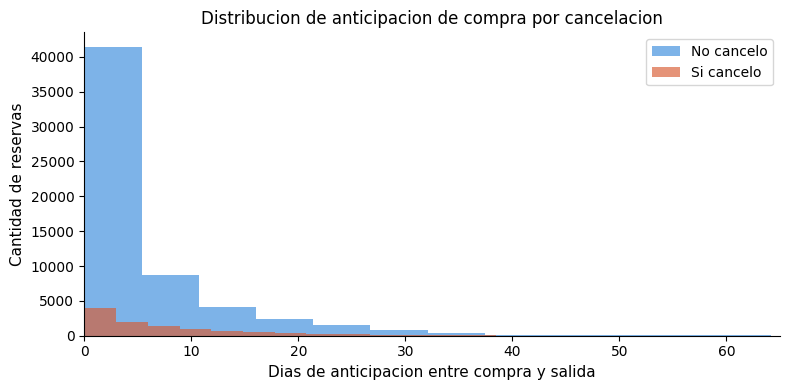

In [ ]:
# --- GRAFICA 1: Dias de anticipacion segun si cancelo o no ---

fig, ax = plt.subplots(figsize=(8, 4))

for val, label, color in [(0, 'No cancelo', '#378ADD'), (1, 'Si cancelo', '#D85A30')]:
    subset = df[df['Cancelled'] == val]['dias_anticipacion']
    ax.hist(subset, bins=40, alpha=0.65, label=label, color=color)

ax.set_xlabel('Dias de anticipacion entre compra y salida', fontsize=11)
ax.set_ylabel('Cantidad de reservas', fontsize=11)
ax.set_title('Distribucion de anticipacion de compra por cancelacion', fontsize=12)
ax.legend()
ax.set_xlim(0, 65) 
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### Observacion - Grafica 1

Se observa que los pasajeros que cancelaron tienden a concentrarse en reservas con pocos dias de anticipacion, pero tambien aparecen cancelaciones en reservas hechas con mucha anticipacion, lo que sugiere que quien reserva demasiado lejos del viaje de todas manera tiene menor probabilidad de cancelar que uno reciente. Los pasajeros que si se presentaron muestran una distribucion mas uniforme. Esta variable sera relevante para el modelo, aunque no es la unica determinante.

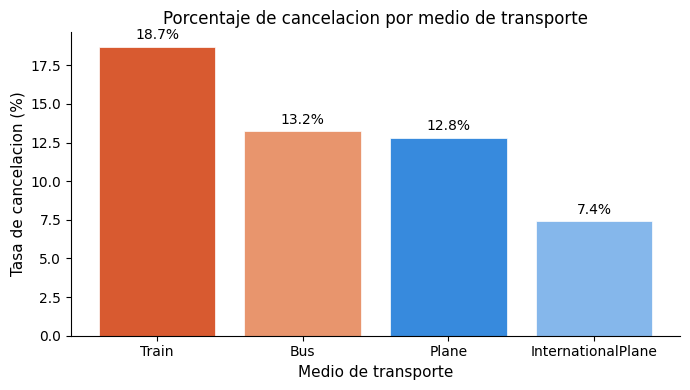

In [7]:
# --- GRAFICA 2: Tasa de cancelacion por medio de transporte ---

# Recuperar etiquetas originales para el grafico
df_plot = df_raw[['ModeOfTravel', 'Cancelled']].dropna()
tasa = df_plot.groupby('ModeOfTravel')['Cancelled'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(tasa.index, tasa.values * 100, color=['#D85A30', '#E8956D', '#378ADD', '#85B7EB'],
              edgecolor='white', linewidth=0.5)

for bar, val in zip(bars, tasa.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            f'{val:.1%}', ha='center', va='bottom', fontsize=10)

ax.set_xlabel('Medio de transporte', fontsize=11)
ax.set_ylabel('Tasa de cancelacion (%)', fontsize=11)
ax.set_title('Porcentaje de cancelacion por medio de transporte', fontsize=12)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### Observacion - Grafica 2

Existe una diferencia clara en la tasa de cancelacion segun el medio de transporte. Esto indica que el tipo de vehiculo tiene un peso significativo en la decision de cancelar: los vuelos internacionales tienden a tener menor cancelacion posiblemente porque el costo es mas alto y el compromiso del viajero es mayor. Los tiquetes de tren, al ser posiblemente mas flexibles y faciles de conseguir, presentan tasas de cancelacion mas altas. Esta variable aportara informacion util al modelo.

In [18]:
# --- SEPARACION EN ENTRENAMIENTO Y PRUEBA ---

X = df.drop(columns=['Cancelled'])
y = df['Cancelled']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y   # mantener proporcion de cancelados en ambos grupos
)

print('Division del dataset:')
print(f'   Entrenamiento : {len(X_train):,} registros (80%)')
print(f'   Prueba        : {len(X_test):,} registros (20%)')
print()
print('   El parametro stratify=y garantiza que el 15% de cancelaciones')
print('   quede representado proporcionalmente en ambos grupos.')

Division del dataset:
   Entrenamiento : 56,568 registros (80%)
   Prueba        : 14,143 registros (20%)

   El parametro stratify=y garantiza que el 15% de cancelaciones
   quede representado proporcionalmente en ambos grupos.


In [24]:
# --- ENTRENAMIENTO DEL MODELO ---

# class_weight='balanced' le indica al modelo que pese mas los cancelados
# porque son minoria (15%). Sin esto, el modelo tenderia a ignorarlos.
modelo = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)

modelo.fit(X_train, y_train)

# Importancia de variables
importancias = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': modelo.feature_importances_
}).sort_values('Importancia', ascending=False).reset_index(drop=True)

print('Modelo entrenado correctamente')
print()
print('Importancia de variables (de mayor a menor):')
display(importancias)
top = importancias.iloc[0]
print()
print(f'Variable mas importante: {top["Variable"]} ({top["Importancia"]:.1%})')
print()
print('Interpretacion:')
print('   La variable StatusofReserve es, por mucho, la más determinante para predecir la cancelación.')
print('   Según los datos:')
print('      - StatusofReserve=2 o 3: nunca se cancelan (reservas seguras).')
print('      - StatusofReserve=4: siempre se cancelan (reservas canceladas).')
print('      - StatusofReserve=5: ~41% se cancelan (estado intermedio/riesgo).')
print('   Esto explica por qué el modelo se apoya principalmente en esta variable.')
print('   El precio y los días de anticipación también aportan, pero en menor medida:')
print('      - Un tiquete costoso compromete más al pasajero.')
print('      - Quien compra con mucha o poca anticipación suele tener mayor incertidumbre sobre sus planes.')

print()
print('Interpretacion de la variable StatusofReserve:')
print()
print(df['StatusofReserve'].value_counts())
print()
print(df.groupby('StatusofReserve')['Cancelled'].mean())

Modelo entrenado correctamente

Importancia de variables (de mayor a menor):


,Variable,Importancia
0,StatusofReserve,0.761372
1,Price,0.092089
2,dias_anticipacion,0.086335
3,ModeOfTravel,0.042961
4,Discounts,0.010828
5,ReasonForTrip,0.002629
6,Gender-Male,0.002058
7,DomesticFlight,0.001728



Variable mas importante: StatusofReserve (76.1%)

Interpretacion:
   La variable StatusofReserve es, por mucho, la más determinante para predecir la cancelación.
   Según los datos:
      - StatusofReserve=2 o 3: nunca se cancelan (reservas seguras).
      - StatusofReserve=4: siempre se cancelan (reservas canceladas).
      - StatusofReserve=5: ~41% se cancelan (estado intermedio/riesgo).
   Esto explica por qué el modelo se apoya principalmente en esta variable.
   El precio y los días de anticipación también aportan, pero en menor medida:
      - Un tiquete costoso compromete más al pasajero.
      - Quien compra con mucha o poca anticipación suele tener mayor incertidumbre sobre sus planes.

Interpretacion de la variable StatusofReserve:

StatusofReserve
3    29766
2    21858
5    14060
4     5027
Name: count, dtype: int64

StatusofReserve
2    0.000000
3    0.000000
4    1.000000
5    0.407112
Name: Cancelled, dtype: float64


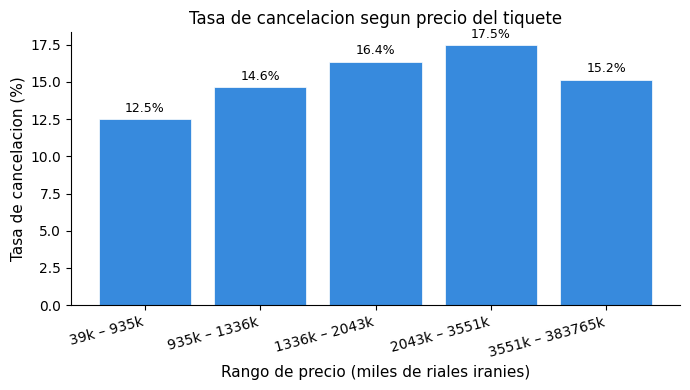

In [14]:
# --- Grafica de barras apiladas: Cancelaciones por rango de precio ---

fig, ax = plt.subplots(figsize=(7, 4))

df_plot = df_raw[['Price', 'Cancelled']].dropna().copy()
df_plot['precio_miles'] = df_plot['Price'] / 1000
df_plot = df_plot[df_plot['precio_miles'] > 0]  # <-- aquí

df_plot['rango_precio'] = pd.qcut(df_plot['precio_miles'], q=5, precision=0, duplicates='drop')

tasa = df_plot.groupby('rango_precio', observed=True)['Cancelled'].mean() * 100
etiquetas = [f"{int(r.left)}k – {int(r.right)}k" for r in tasa.index]

bars = ax.bar(etiquetas, tasa.values, color='#378ADD', edgecolor='white', linewidth=0.5)

for bar, val in zip(bars, tasa.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            f'{val:.1f}%', ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Rango de precio (miles de riales iranies)', fontsize=11)
ax.set_ylabel('Tasa de cancelacion (%)', fontsize=11)
ax.set_title('Tasa de cancelacion segun precio del tiquete', fontsize=12)
ax.spines[['top', 'right']].set_visible(False)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

### Observacion - Grafica 3

Los tiquetes en el dataset van desde precios muy bajos de alrededor de 1 USD hasta casos excepcionales cercanos a 9,200 USD, aunque la gran mayoría se concentra entre 22 y 85 USD. La tasa de cancelación se mantiene relativamente estable entre el 12% y el 17% a lo largo de todos los rangos de precio, lo que indica que el precio no es un factor determinante para predecir si un pasajero cancelará o no, y explica por qué el modelo le asignó apenas un 9% de importancia frente al 76% que le dio al estado de la reserva.

In [29]:
# --- PREDICCIONES ---

y_pred = modelo.predict(X_test)

# Tabla comparativa: prediccion vs realidad
resultados = X_test.copy()
resultados['cancelación real']       = y_test.values
resultados['cancelación predicción'] = y_pred
resultados['correcto']   = (resultados['cancelación real'] == resultados['cancelación predicción']).map({True: 'Si', False: 'No'})

print('Comparacion prediccion vs realidad (primeros 15 registros de prueba):')
display(resultados[['dias_anticipacion', 'Price', 'ModeOfTravel', 'cancelación real', 'cancelación predicción', 'correcto']].head(15))

Comparacion prediccion vs realidad (primeros 15 registros de prueba):


,dias_anticipacion,Price,ModeOfTravel,cancelación real,cancelación predicción,correcto
26737,5.195562,2535000.0,0,0,0,Si
16671,0.213953,520000.0,0,0,0,Si
54977,1.489141,1950000.0,0,0,0,Si
55006,7.331473,1319000.0,3,0,0,Si
12936,16.455396,2043000.0,3,0,0,Si
64908,4.043612,12405000.0,2,0,0,Si
57589,0.416943,2150000.0,0,0,0,Si
21700,0.945268,2750000.0,0,0,0,Si
59934,8.792911,3014000.0,3,0,0,Si
45608,0.182877,1000000.0,0,0,0,Si


In [30]:
# --- EVALUACION DEL MODELO ---

accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy del modelo: {accuracy:.1%}')
print(f'de cada 10 reservas, el modelo clasifica')
print(f'correctamente aproximadamente {round(accuracy * 10)} si el pasajero cancelara o no.')
print()

Accuracy del modelo: 98.3%
de cada 10 reservas, el modelo clasifica
correctamente aproximadamente 10 si el pasajero cancelara o no.



In [12]:
# --- VALIDACION CRUZADA ---

scores = cross_val_score(modelo, X, y, cv=5, scoring='accuracy')

print('Validacion cruzada (5 divisiones):')
for i, s in enumerate(scores, 1):
    print(f'   Fold {i}: {s:.1%}')
print(f'Promedio: {scores.mean():.1%}')
print()
print('Una variacion baja entre folds indica que el modelo es estable')
print('y no depende de un subconjunto particular de los datos.')

Validacion cruzada (5 divisiones):
   Fold 1: 98.2%
   Fold 2: 98.3%
   Fold 3: 98.3%
   Fold 4: 98.2%
   Fold 5: 98.2%
Promedio: 98.2%

Una variacion baja entre folds indica que el modelo es estable
y no depende de un subconjunto particular de los datos.


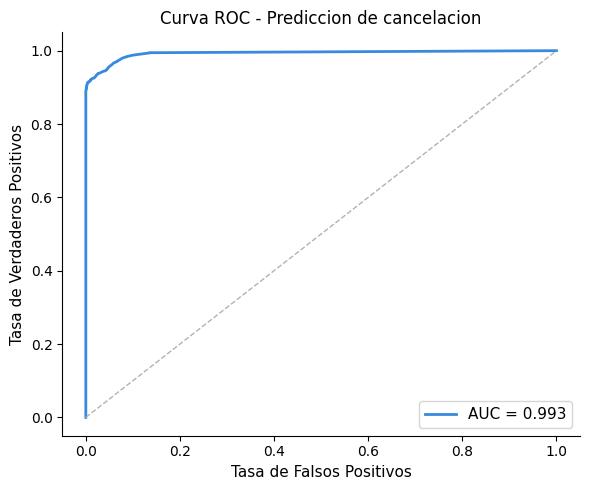

AUC: 0.993
Un AUC cercano a 1.0 indica que el modelo distingue bien entre
pasajeros que cancelan y los que no. Un AUC de 0.5 equivaldria
a adivinar al azar.


In [13]:
# --- CURVA ROC Y AUC ---

y_prob = modelo.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, color='#378ADD', lw=2, label=f'AUC = {auc:.3f}')
ax.plot([0, 1], [0, 1], '--', color='#B4B2A9', lw=1)
ax.set_xlabel('Tasa de Falsos Positivos', fontsize=11)
ax.set_ylabel('Tasa de Verdaderos Positivos', fontsize=11)
ax.set_title('Curva ROC - Prediccion de cancelacion', fontsize=12)
ax.legend(fontsize=11)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

print(f'AUC: {auc:.3f}')
print('Un AUC cercano a 1.0 indica que el modelo distingue bien entre')
print('pasajeros que cancelan y los que no. Un AUC de 0.5 equivaldria')
print('a adivinar al azar.')

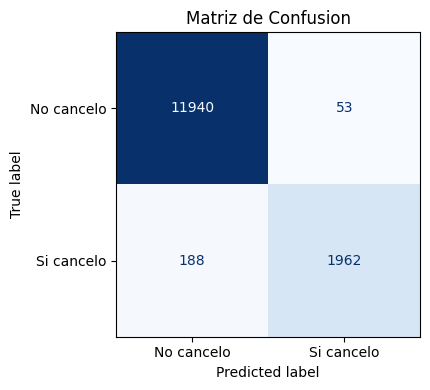

Desglose de la matriz:
   Verdaderos Negativos (TN): 11,940  - predijo no cancela y era correcto
   Falsos Positivos     (FP): 53   - predijo cancela pero el pasajero si fue
   Falsos Negativos     (FN): 188   - predijo no cancela pero si cancelo
   Verdaderos Positivos (TP): 1,962  - predijo cancela y era correcto

Para la agencia, los Falsos Negativos son los mas costosos:
son los pasajeros que el modelo no detecto y cancelaron de sorpresa.


In [14]:
# --- MATRIZ DE CONFUSION ---

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No cancelo', 'Si cancelo'])

fig, ax = plt.subplots(figsize=(5, 4))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Matriz de Confusion', fontsize=12)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print('Desglose de la matriz:')
print(f'   Verdaderos Negativos (TN): {tn:,}  - predijo no cancela y era correcto')
print(f'   Falsos Positivos     (FP): {fp:,}   - predijo cancela pero el pasajero si fue')
print(f'   Falsos Negativos     (FN): {fn:,}   - predijo no cancela pero si cancelo')
print(f'   Verdaderos Positivos (TP): {tp:,}  - predijo cancela y era correcto')
print()
print('Para la agencia, los Falsos Negativos son los mas costosos:')
print('son los pasajeros que el modelo no detecto y cancelaron de sorpresa.')

# Ejemplo: prediccion sobre una reserva ficticia

A continuacion se construye manualmente una reserva con valores especificos para cada variable, y el modelo predice si ese pasajero cancelara o no.

Los valores de `ModeOfTravel` y `ReasonForTrip` deben ser numericos porque fueron codificados con LabelEncoder. Para saber que numero corresponde a cada categoria, se puede revisar el orden alfabetico que usa LabelEncoder: Bus=0, InternationalPlane=1, Plane=2, Train=3 y para ReasonForTrip: Int=0, Work=1.

In [15]:
# --- PREDICCION SOBRE RESERVA FICTICIA ---

# Perfil: pasajero hombre, viaja en avion domestico por trabajo,
# compro con 2 dias de anticipacion, tiquete costoso, sin descuento
reserva_nueva = pd.DataFrame([{
    'dias_anticipacion': 2,
    'Price':             850000,
    'Discounts':         0,
    'Gender-Male':       1,
    'DomesticFlight':    1,
    'ModeOfTravel':      2,   # 2 = Plane
    'ReasonForTrip':     1,   # 1 = Work
    'StatusofReserve':   3
}])

prediccion   = modelo.predict(reserva_nueva)[0]
probabilidad = modelo.predict_proba(reserva_nueva)[0]

print('Reserva ingresada:')
display(reserva_nueva)
print()
print(f'Resultado del modelo: {"CANCELARA" if prediccion == 1 else "NO CANCELARA"}')
print(f'Probabilidad de no cancelar : {probabilidad[0]:.1%}')
print(f'Probabilidad de cancelar    : {probabilidad[1]:.1%}')
print()
print('Interpretacion:')
if prediccion == 1:
    print('El modelo considera que este pasajero tiene alto riesgo de cancelar.')
    print('La agencia podria tomar medidas preventivas como contacto anticipado')
    print('o aplicar politicas de reembolso mas estrictas para esta reserva.')
else:
    print('El modelo considera que este pasajero muy probablemente se presentara.')
    print('No se requiere intervencion preventiva para esta reserva.')

Reserva ingresada:


,dias_anticipacion,Price,Discounts,Gender-Male,DomesticFlight,ModeOfTravel,ReasonForTrip,StatusofReserve
0,2,850000,0,1,1,2,1,3



Resultado del modelo: NO CANCELARA
Probabilidad de no cancelar : 100.0%
Probabilidad de cancelar    : 0.0%

Interpretacion:
El modelo considera que este pasajero muy probablemente se presentara.
No se requiere intervencion preventiva para esta reserva.
